# Titanic — сравнение моделей

Цель — предсказать `Survived`, сравнить модели и проверить, когда помогают настройка и новые признаки. Основная метрика — **CV accuracy**, дополнительная — **CV ROC-AUC**. Для sklearn-моделей используем `StratifiedKFold(5, shuffle=True, random_state=42)`; отдельные запуски `catboost.cv` используют другое разбиение и не входят в строгий рейтинг. У каждой модели ниже есть вопрос, эксперимент и короткий вывод.

In [12]:
import os
import sys
from pathlib import Path

# Ядро может стартовать из корня проекта или из notebooks.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "config.yaml").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "config.yaml").is_file() or not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError("Откройте ноутбук из корня Titanic-ML или папки notebooks")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)  # Пути в конфиге и ячейках заданы от корня проекта.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier, Pool, cv
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from src.sklearn_experiments import (
    base_config,
    evaluate_cv,
    evaluate_model,
    get_cv,
    tune_model,
)

%load_ext autoreload
%autoreload 2

In [13]:
df_train = pd.read_csv("data/train.csv")

## Baseline — DummyClassifier

Предсказывает самый частый класс. Оцениваем на тех же пяти фолдах, что и остальные sklearn-модели.


In [3]:
dummy_scores = cross_val_score(
    DummyClassifier(strategy="most_frequent"),
    df_train[["Sex"]],
    df_train["Survived"],
    cv=get_cv(),
    scoring="accuracy",
)
pd.Series({"CV accuracy": dummy_scores.mean(), "std": dummy_scores.std()})


CV accuracy    0.616163
std            0.002325
dtype: float64

## Logistic Regression

Сначала оцениваем базовые признаки, затем новые признаки и регуляризацию. Предобработка внутри pipeline обучается отдельно на каждом фолде.


In [4]:
logreg_model = LogisticRegression(max_iter=1000, random_state=42)
logreg_baseline = evaluate_model(
    df=df_train,
    target="Survived",
    model=logreg_model,
    config=base_config,
)
logreg_baseline


{'accuracy_mean': np.float64(0.7923984683949532),
 'accuracy_std': np.float64(0.018750529151998523),
 'roc_auc_mean': np.float64(0.8519052001988017),
 'roc_auc_std': np.float64(0.021477125487472243)}

In [5]:
logreg_best_config = {
    "features": {
        "Age": "numeric",
        "Sex": "binary",
        "Embarked": "onehot",
        "Pclass": "onehot",
        "_Fare": "numeric",
        "SibSp": "numeric",
        "Parch": "numeric",
    },

    "fare_log1p": True,
    "sex_pclass": True,
    "age_squared": True,
    "is_alone": True,

    "is_child": False,
    "family_size": False,
    "scale_numeric": True,
}

best_feature_result = evaluate_model(
    df=df_train,
    target="Survived",
    model=logreg_model,
    config=logreg_best_config,
)

best_feature_result


{'accuracy_mean': np.float64(0.8159437574540205),
 'accuracy_std': np.float64(0.008091836959853813),
 'roc_auc_mean': np.float64(0.8639580262608725),
 'roc_auc_std': np.float64(0.012196395216648746)}

### Регуляризация и подбор параметров

Проверяем, даст ли настройка регуляризации прирост при тех же признаках: `l1_ratio=0` — L2, `1` — L1, промежуточные значения — ElasticNet. Параметр `C` управляет силой регуляризации; для всех вариантов используем `solver="saga"`.

In [6]:
tuned_model = LogisticRegression(
    solver="saga",
    max_iter=1000,
    random_state=42,
)

param_grid = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "model__l1_ratio": [0.0, 0.25, 0.5, 0.75, 1.0],
}

grid_features = tune_model(
    df=df_train,
    target="Survived",
    model=tuned_model,
    param_grid=param_grid,
    config=logreg_best_config,
)

print("Best accuracy:", grid_features.best_score_)
print("Best params:", grid_features.best_params_)
print(
    "Iterations:",
    grid_features.best_estimator_.named_steps["model"].n_iter_,
)


Best accuracy: 0.8159437574540205
Best params: {'model__C': 1, 'model__l1_ratio': 0.0}
Iterations: [187]


### Что дало улучшение?

Повторяем подбор на исходных признаках, чтобы отделить эффект настройки от эффекта новых признаков.


In [7]:
grid_base = tune_model(
    df=df_train,
    target="Survived",
    model=tuned_model,
    param_grid=param_grid,
    config=base_config,
)

print("Tuned base features:", grid_base.best_score_)
print("Best params:", grid_base.best_params_)


Tuned base features: 0.8024794425961961
Best params: {'model__C': 0.1, 'model__l1_ratio': 0.0}


### Logistic Regression — итог

| Вариант | CV accuracy |
| --- | ---: |
| Базовые признаки | 0.7924 |
| Базовые признаки + подбор | 0.8025 |
| Новые признаки + подбор | **0.8159** |

Лучшие `C=1`, L2. Наибольший прирост дали новые признаки; L1 и ElasticNet лучший результат не улучшили.


## KNN

Для метода расстояний масштабируем числовые признаки. Проверяем параметры и состав признаков.


In [8]:

knn_base_config = {
    "features": {
        "Age": "numeric",
        "Fare": "numeric",
        "Sex": "binary",
        "Embarked": "onehot",
        "Pclass": "numeric",
        "SibSp": "numeric",
        "Parch": "numeric",
    },
    "scale_numeric": True,
}

knn_baseline = evaluate_model(
    df=df_train,
    target="Survived",
    model=KNeighborsClassifier(),
    config=knn_base_config,
)

knn_baseline


{'accuracy_mean': np.float64(0.8047266336074321),
 'accuracy_std': np.float64(0.02246132953142063),
 'roc_auc_mean': np.float64(0.84881001644593),
 'roc_auc_std': np.float64(0.026386557561435802)}

In [9]:
param_grid_knn = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"],
    "model__metric": ["euclidean", "manhattan"],
}

grid_knn = tune_model(
    df=df_train,
    target="Survived",
    model=KNeighborsClassifier(),
    param_grid=param_grid_knn,
    config=knn_base_config,
)

print("Best accuracy:", grid_knn.best_score_)
print("Best params:", grid_knn.best_params_)


Best accuracy: 0.8148201619484026
Best params: {'model__metric': 'manhattan', 'model__n_neighbors': 21, 'model__weights': 'uniform'}


In [10]:
knn_best_config = {
    "features": {
        "Age": "numeric",
        "_Fare": "numeric",
        "Sex": "onehot",
        "Embarked": "onehot",
        "Pclass": "numeric",
        "SibSp": "numeric",
        "Parch": "numeric",
    },
    "scale_numeric": True,
    "family_size": True,
    "is_alone": False,
    "is_child": False,
    "fare_log1p": False,
    "age_squared": False,
    "sex_pclass": False,
}

best_knn = KNeighborsClassifier(
    n_neighbors=21,
    weights="uniform",
    metric="manhattan",
)

knn_best_result = evaluate_model(
    df=df_train,
    target="Survived",
    model=best_knn,
    config=knn_best_config,
)

knn_best_result


{'accuracy_mean': np.float64(0.8316552633230808),
 'accuracy_std': np.float64(0.008585631966684338),
 'roc_auc_mean': np.float64(0.8582623218268705),
 'roc_auc_std': np.float64(0.023367825986457164)}

### KNN — итог

CV accuracy: **0.8047 → 0.8148 → 0.8317** (baseline → подбор → подбор с новыми признаками). Лучший вариант: 21 сосед, Manhattan, `FamilySize`, one-hot для `Sex`, без `Fare`. Без масштабирования качество снижалось примерно до 0.781.


## Decision Tree

Проверяем переобучение неограниченного дерева и ограничения его сложности.


In [11]:
tree_config = {
    "features": {
        "Age": "numeric",
        "Fare": "numeric",
        "Sex": "binary",
        "Embarked": "onehot",
        "Pclass": "numeric",
        "SibSp": "numeric",
        "Parch": "numeric",
    },
    "scale_numeric": False,
}

dt_baseline = evaluate_model(
    df=df_train,
    target="Survived",
    model=DecisionTreeClassifier(random_state=42),
    config=tree_config,
)

dt_baseline


{'accuracy_mean': np.float64(0.7878789780930262),
 'accuracy_std': np.float64(0.03105183159581353),
 'roc_auc_mean': np.float64(0.7822737031498969),
 'roc_auc_std': np.float64(0.03154599971106935)}

In [12]:
param_grid_dt = {
    "model__max_depth": [7, 8, 9],
    "model__min_samples_split": [8, 10, 12, 15],
    "model__min_samples_leaf": [1, 2, 3],
    "model__criterion": ["gini", "entropy"],
}

grid_dt = tune_model(
    df=df_train,
    target="Survived",
    model=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid_dt,
    config=tree_config,
)

print("Best accuracy:", grid_dt.best_score_)
print("Best params:", grid_dt.best_params_)


Best accuracy: 0.8383780051471973
Best params: {'model__criterion': 'gini', 'model__max_depth': 8, 'model__min_samples_leaf': 1, 'model__min_samples_split': 10}


In [13]:
tree_best_config = {
    "features": {
        "Age": "numeric",
        "Fare": "numeric",
        "Sex": "binary",
        "Embarked": "onehot",
        "Pclass": "numeric",
        "SibSp": "numeric",
        "Parch": "numeric",
    },
    "scale_numeric": False,
    "sex_pclass": True,
}

best_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=1,
    random_state=42,
)

tree_best_result = evaluate_model(
    df=df_train,
    target="Survived",
    model=best_tree,
    config=tree_best_config,
)

tree_best_result


{'accuracy_mean': np.float64(0.8428661100998054),
 'accuracy_std': np.float64(0.020149654339052248),
 'roc_auc_mean': np.float64(0.8471923924953091),
 'roc_auc_std': np.float64(0.021245244391572174)}

### Decision Tree — итог

CV accuracy: **0.7879 → 0.8384 → 0.8429** (baseline → подбор → `SexPclass`). Ограничения уменьшили разрыв между train (0.9798 у baseline) и CV; лучший результат дал `max_depth=8`, `min_samples_split=10`.


## Random Forest

Сравниваем стандартный лес с моделью, у которой ограничен размер листьев и узлов.


In [15]:

rf_config = {
    "features": {
        "Age": "numeric",
        "Fare": "numeric",
        "Sex": "binary",
        "Embarked": "onehot",
        "Pclass": "numeric",
        "SibSp": "numeric",
        "Parch": "numeric",
    },
    "scale_numeric": False,
}

rf_baseline = evaluate_model(
    df=df_train,
    target="Survived",
    model=RandomForestClassifier(random_state=42),
    config=rf_config,
)

rf_baseline


{'accuracy_mean': np.float64(0.8125353085179838),
 'accuracy_std': np.float64(0.027165574553443112),
 'roc_auc_mean': np.float64(0.8717166888149901),
 'roc_auc_std': np.float64(0.02668116435774144)}

In [15]:
param_grid_rf = {
    "model__max_depth": [4, 6, 8, 10, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2", None],
}

grid_rf = tune_model(
    df=df_train,
    target="Survived",
    model=RandomForestClassifier(
        n_estimators=200,
        random_state=42,
    ),
    param_grid=param_grid_rf,
    config=rf_config,
)

print("Best accuracy:", grid_rf.best_score_)
print("Best params:", grid_rf.best_params_)


Best accuracy: 0.8462117883372041
Best params: {'model__max_depth': None, 'model__max_features': None, 'model__min_samples_leaf': 4, 'model__min_samples_split': 10}


In [16]:
best_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    max_features=None,
    min_samples_leaf=4,
    min_samples_split=10,
    random_state=42,
)

rf_best_result = evaluate_model(
    df=df_train,
    target="Survived",
    model=best_rf,
    config=rf_config,
)

rf_best_result


{'accuracy_mean': np.float64(0.8462117883372041),
 'accuracy_std': np.float64(0.021072124467657417),
 'roc_auc_mean': np.float64(0.8810902698824753),
 'roc_auc_std': np.float64(0.025174804818725843)}

### Random Forest — итог

CV accuracy: **0.8125 → 0.8462 ± 0.0211** после настройки. Лучшие ограничения: `min_samples_leaf=4`, `min_samples_split=10`, `max_features=None`, 200 деревьев. Дополнительные признаки заметного прироста не дали.


## CatBoost

Семь признаков; `Sex`, `Embarked`, `Pclass` передаём как категории. Основная метрика — CV accuracy. Полный пересчёт поиска и CV в этом разделе может занять несколько минут.


In [17]:
X = df_train[
    [
        "Age",
        "Fare",
        "Sex",
        "Embarked",
        "Pclass",
        "SibSp",
        "Parch",
    ]
].copy()

y = df_train["Survived"]

cat_features = [
    "Sex",
    "Embarked",
    "Pclass",
]

for col in cat_features:
    X[col] = X[col].fillna("Missing").astype(str)

In [ ]:

catboost_config = {
    "features": [
        "Age", "Fare", "Sex", "Embarked",
        "Pclass", "SibSp", "Parch",''
    ],
    "cat_features": [
        "Sex", "Embarked", "Pclass", 
    ],
    "categorical_nan": "Missing",
    "numeric_nan": "native",
}

In [19]:
catboost_model = CatBoostClassifier(
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
)
catboost_baseline = evaluate_cv(
    estimator=catboost_model,
    X=X,
    y=y,
    model=catboost_model,
    config=catboost_config,
    fit_params={"cat_features": cat_features},
)
catboost_baseline


{'accuracy_mean': np.float64(0.819295712761283),
 'accuracy_std': np.float64(0.016520987924802708),
 'roc_auc_mean': np.float64(0.8759317618333551),
 'roc_auc_std': np.float64(0.017435455520819567)}

In [20]:
pool = Pool(X, y, cat_features=cat_features)
catboost_baseline_params = {
    "loss_function": "Logloss",
    "custom_metric": ["Accuracy", "AUC"],
    "random_seed": 42,
    "verbose": False,
    "allow_writing_files": False,
}
catboost_baseline_cv = cv(
    pool=pool,
    params=catboost_baseline_params,
    folds=get_cv(),
)
catboost_baseline_cv.iloc[-1][
    ["test-Accuracy-mean", "test-Accuracy-std", "test-AUC-mean"]
]


e:\ML_CLAN\Titanic-ML\.venv\Lib\site-packages\sklearn\model_selection\_split.py:884: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(


Training on fold [0/5]

bestTest = 0.3879200435
bestIteration = 494

Training on fold [1/5]

bestTest = 0.3922053676
bestIteration = 499

Training on fold [2/5]

bestTest = 0.4447447477
bestIteration = 148

Training on fold [3/5]

bestTest = 0.3961852383
bestIteration = 229

Training on fold [4/5]

bestTest = 0.396913586
bestIteration = 718



test-Accuracy-mean    0.836125
test-Accuracy-std     0.023075
test-AUC-mean         0.872951
Name: 999, dtype: float64

### Подбор параметров

Проверяем 20 случайных сочетаний `depth`, `learning_rate`, `l2_leaf_reg` и `random_strength` на одном разбиении 80/20. По Logloss здесь выбраны `depth=7`, `learning_rate=0.1`, `l2_leaf_reg=3`, `random_strength=0`; затем оцениваем их через `catboost.cv`. Этот поиск и последующий CV используют разную валидацию.

In [21]:
catboost_search_model = CatBoostClassifier(
    iterations=2000,
    loss_function="Logloss",
    eval_metric="Logloss",
    custom_metric=["Accuracy"],
    early_stopping_rounds=100,
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
)

param_distributions = {
    "depth": [4, 5, 6, 7, 8],
    "learning_rate": [0.02, 0.03, 0.05, 0.07, 0.1],
    "l2_leaf_reg": [1, 3, 5, 10, 20],
    "random_strength": [0, 0.5, 1, 2, 5],
}

random_result = catboost_search_model.randomized_search(
    param_distributions=param_distributions,
    X=pool,
    n_iter=20,
    search_by_train_test_split=True,
    train_size=0.8,
    partition_random_seed=42,
    shuffle=True,
    stratified=True,
    calc_cv_statistics=False,
    refit=False,
    verbose=False,
)

random_result["params"]

Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.4279471252
bestIteration = 274

Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.4308007007
bestIteration = 768

Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.4193070603
bestIteration = 179

Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.4247366702
bestIteration = 232

Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.4289386998
bestIteration = 256

Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.4214231061
bestIteration = 80

Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.4200892885
bestIteration = 350

Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.412118199
bestIteration = 247

Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.4251413659
bestIteration = 271

Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.4119291387
bestIteration

{'random_strength': 0, 'depth': 7, 'learning_rate': 0.1, 'l2_leaf_reg': 3}

In [22]:
best_search_params = random_result["params"]
cv_params = {
    **best_search_params,
    "iterations": 1500,
    "loss_function": "Logloss",
    "eval_metric": "Logloss",
    "custom_metric": ["Accuracy", "AUC"],
    "random_seed": 42,
    "verbose": False,
    "allow_writing_files": False,
}
tuned_cv_results = cv(
    pool=pool,
    params=cv_params,
    fold_count=5,
    stratified=True,
    shuffle=True,
    partition_random_seed=42,
    early_stopping_rounds=100,
)
best_accuracy_row = tuned_cv_results.loc[
    tuned_cv_results["test-Accuracy-mean"].idxmax()
]
pd.Series({
    "Количество деревьев": int(best_accuracy_row["iterations"]) + 1,
    "CV accuracy": best_accuracy_row["test-Accuracy-mean"],
    "std": best_accuracy_row["test-Accuracy-std"],
    "CV ROC-AUC": best_accuracy_row["test-AUC-mean"],
})


Training on fold [0/5]

bestTest = 0.3602061179
bestIteration = 33

Training on fold [1/5]

bestTest = 0.4939691993
bestIteration = 12

Training on fold [2/5]

bestTest = 0.4437430858
bestIteration = 26

Training on fold [3/5]

bestTest = 0.3024646786
bestIteration = 299

Training on fold [4/5]

bestTest = 0.4528169582
bestIteration = 13



Количество деревьев    110.000000
CV accuracy              0.832758
std                      0.039783
CV ROC-AUC               0.866633
dtype: float64

### Кривые обучения

Синий — train, оранжевый — CV; слева Logloss (меньше лучше), справа accuracy (больше лучше). CV-кривые быстро выходят на плато, а train продолжает улучшаться — модель подгоняет обучающие данные.


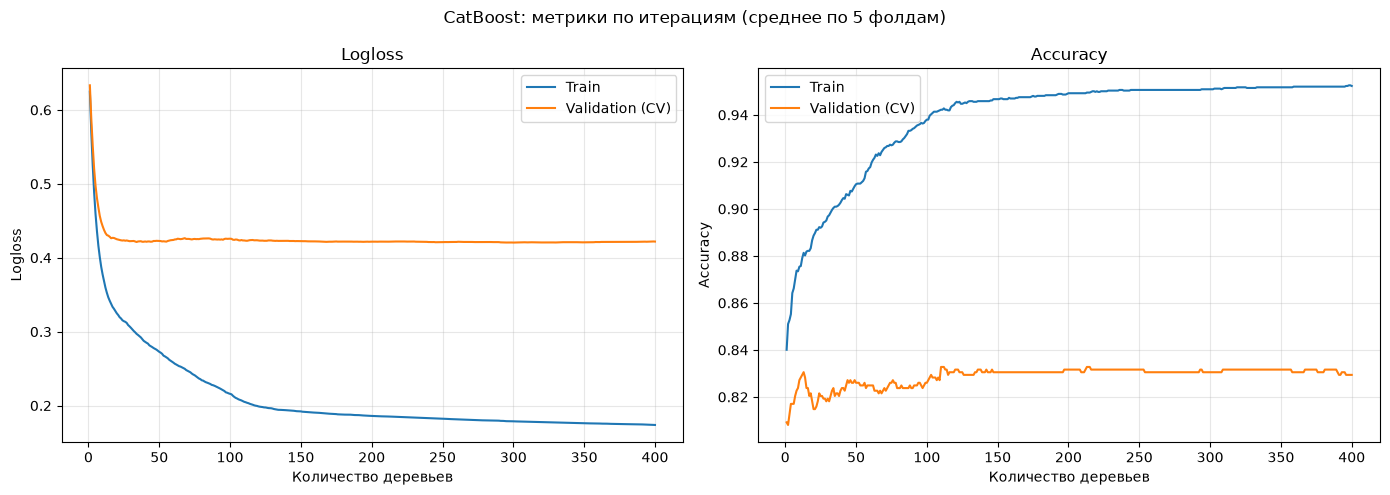

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

for ax, metric in zip(axes, ["Logloss", "Accuracy"]):
    ax.plot(
        tuned_cv_results["iterations"] + 1,
        tuned_cv_results[f"train-{metric}-mean"],
        label="Train",
        color="tab:blue",
    )
    ax.plot(
        tuned_cv_results["iterations"] + 1,
        tuned_cv_results[f"test-{metric}-mean"],
        label="Validation (CV)",
        color="tab:orange",
    )
    ax.set(title=metric, xlabel="Количество деревьев", ylabel=metric)
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle("CatBoost: метрики по итерациям (среднее по 5 фолдам)")
fig.tight_layout()
plt.show()

### Важность признаков

Обучаем выбранную модель с 110 деревьями на всём train и смотрим, какие признаки она использовала. Важность внутри модели подсказывает гипотезы, но сама по себе не показывает прирост CV accuracy от признака.

In [24]:
best_cat_model = CatBoostClassifier(
    **best_search_params,
    iterations=int(best_accuracy_row["iterations"]) + 1,
    loss_function="Logloss",
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
)
best_cat_model.fit(X, y, cat_features=cat_features)
importance = pd.Series(
    best_cat_model.get_feature_importance(),
    index=X.columns,
).sort_values(ascending=False)


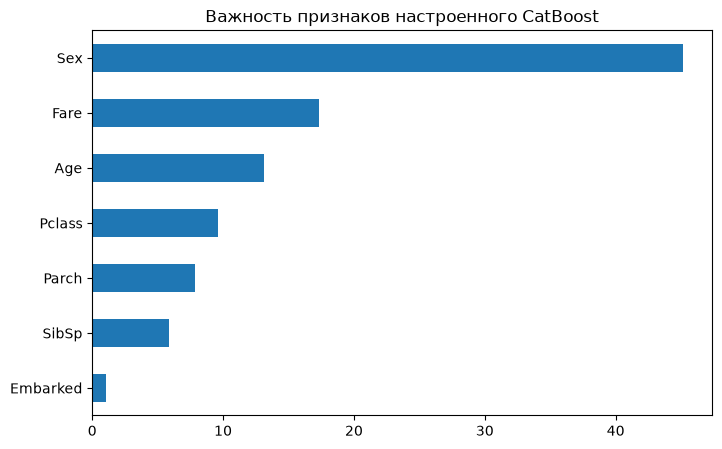

In [25]:
importance.sort_values().plot.barh(
    figsize=(8, 5),
    title="Важность признаков настроенного CatBoost",
);

### CatBoost — новые признаки

Проверяем `FamilySize`, титул из `Name` и палубу из `Cabin`. Во всех вариантах — одни параметры, 110 деревьев и одинаковое разбиение `catboost.cv`.


In [26]:
feature_data = X.copy()
titles = df_train["Name"].str.extract(r",\s*([^.]*)\.", expand=False).fillna("Other")
feature_data["Title"] = titles.where(titles.isin(["Mr", "Mrs", "Miss", "Master"]), "Other")
feature_data["FamilySize"] = df_train["SibSp"] + df_train["Parch"] + 1
feature_data["Deck"] = df_train["Cabin"].str[0].fillna("Missing")

feature_variants = {
    "Baseline": [],
    "FamilySize": ["FamilySize"],
    "Title": ["Title"],
    "Deck": ["Deck"],
    "Все три": ["FamilySize", "Title", "Deck"],
}

feature_cv_params = {
    **best_search_params,
    "iterations": int(best_accuracy_row["iterations"]) + 1,
    "loss_function": "Logloss",
    "eval_metric": "Logloss",
    "custom_metric": ["Accuracy", "AUC"],
    "random_seed": 42,
    "verbose": False,
    "allow_writing_files": False,
}

feature_scores = []
for name, added in feature_variants.items():
    columns = list(X.columns) + added
    categorical = cat_features + [col for col in added if col in ("Title", "Deck")]
    fold_results = cv(
        pool=Pool(feature_data[columns], y, cat_features=categorical),
        params=feature_cv_params,
        fold_count=5,
        stratified=True,
        shuffle=True,
        partition_random_seed=42,
        verbose=False,
    )
    last = fold_results.iloc[-1]
    feature_scores.append({
        "Признаки": name,
        "CV accuracy": last["test-Accuracy-mean"],
        "std": last["test-Accuracy-std"],
        "CV ROC-AUC": last["test-AUC-mean"],
    })

feature_results = pd.DataFrame(feature_scores).sort_values("CV accuracy", ascending=False)


Training on fold [0/5]

bestTest = 0.357873532
bestIteration = 60

Training on fold [1/5]

bestTest = 0.4927713367
bestIteration = 10

Training on fold [2/5]

bestTest = 0.4540286048
bestIteration = 26

Training on fold [3/5]

bestTest = 0.316272645
bestIteration = 109

Training on fold [4/5]

bestTest = 0.454326909
bestIteration = 30

Training on fold [0/5]

bestTest = 0.3553061616
bestIteration = 52

Training on fold [1/5]

bestTest = 0.4842423516
bestIteration = 12

Training on fold [2/5]

bestTest = 0.4370729095
bestIteration = 109

Training on fold [3/5]

bestTest = 0.3360739948
bestIteration = 106

Training on fold [4/5]

bestTest = 0.4599765581
bestIteration = 51

Training on fold [0/5]

bestTest = 0.3475899661
bestIteration = 88

Training on fold [1/5]

bestTest = 0.4954042533
bestIteration = 8

Training on fold [2/5]

bestTest = 0.4353562299
bestIteration = 68

Training on fold [3/5]

bestTest = 0.3194677101
bestIteration = 107

Training on fold [4/5]

bestTest = 0.4475946741


| Признаки | CV accuracy | std | CV ROC-AUC |
| --- | ---: | ---: | ---: |
| Baseline | 0.8238 | 0.0551 | 0.8638 |
| `FamilySize` | 0.8204 | 0.0456 | 0.8704 |
| `Title` | **0.8316** | 0.0466 | 0.8665 |
| `Deck` | 0.8260 | 0.0475 | 0.8578 |
| Все три | 0.8282 | 0.0444 | 0.8661 |

`Title` дал лучший результат (+0.0078 CV accuracy к baseline). Разница мала относительно разброса между фолдами; остальные варианты CV accuracy не улучшили. Числа выше получены при **фиксированных 110 деревьях**, поэтому отличаются от максимума по всей предыдущей CV-кривой.


### CatBoost — итог

- Baseline: **0.8193 ± 0.0165** CV accuracy через sklearn; **0.8361 ± 0.0231** через `catboost.cv`.
- После поиска параметров: **0.8328 ± 0.0398** на 110 деревьях. Подтверждённого прироста нет: поиск шёл по Logloss, последний CV — на других фолдах.
- При фиксированных 110 деревьях `Title` улучшил CV accuracy с **0.8238 до 0.8316**; это небольшая разница на пяти фолдах.
- CV-кривые выходят на плато, пока train улучшается. Самые важные исходные признаки: `Sex`, `Fare`, `Age`.
- Лучший Random Forest: **0.8462 ± 0.0211** на общих фолдах. С результатом CatBoost сравнение ориентировочное.


## LightGBM

Сначала сравним общий pipeline с предобработкой и встроенную обработку категорий LightGBM на тех же семи признаках и пяти фолдах. Затем посмотрим кривые обучения и подберём параметры, связанные с переобучением.

### Baseline: два способа обработки категорий

In [19]:
lgbm_preprocessed_baseline = evaluate_model(
    df=df_train,
    target="Survived",
    model=LGBMClassifier(random_state=42, verbosity=-1),
    config=rf_config,
)

lgbm_preprocessed_baseline

{'accuracy_mean': np.float64(0.8271357730211537),
 'accuracy_std': np.float64(0.019777287052572288),
 'roc_auc_mean': np.float64(0.8795168732539975),
 'roc_auc_std': np.float64(0.024002547103078177)}

In [28]:

lgbm_features = ["Age", "Fare", "Sex", "Embarked", "Pclass", "SibSp", "Parch"]
lgbm_categories = ["Sex", "Embarked", "Pclass"]

X_lgbm = df_train[lgbm_features].copy()
y_lgbm = df_train["Survived"]

for column in lgbm_categories:
    X_lgbm[column] = X_lgbm[column].astype("category")

In [29]:
lgbm_model = LGBMClassifier(random_state=42, verbosity=-1)

lgbm_native_baseline = evaluate_cv(
    estimator=lgbm_model,
    X=X_lgbm,
    y=y_lgbm,
    model=lgbm_model,
    config={"features": lgbm_features, "cat_features": lgbm_categories},
)

lgbm_native_baseline

{'accuracy_mean': np.float64(0.8260184545853996),
 'accuracy_std': np.float64(0.024223598920035193),
 'roc_auc_mean': np.float64(0.8799536787191939),
 'roc_auc_std': np.float64(0.02005012088831701)}

Общая предобработка: **0.8271 ± 0.0198** CV accuracy; встроенные категории: **0.8260 ± 0.0242**. Разница мала. Для изучения LightGBM дальше используем его встроенную обработку категорий и пропусков.

### Кривые обучения

Построим train и validation Logloss и Accuracy по числу деревьев на тех же пяти фолдах. Так проверим, когда модель перестаёт улучшаться на новых данных.

In [30]:
lgbm_curves = []

for train_idx, valid_idx in get_cv().split(X_lgbm, y_lgbm):
    X_train_fold = X_lgbm.iloc[train_idx]
    X_valid_fold = X_lgbm.iloc[valid_idx]
    y_train_fold = y_lgbm.iloc[train_idx]
    y_valid_fold = y_lgbm.iloc[valid_idx]

    fold_model = clone(lgbm_model)
    fold_model.fit(
        X_train_fold,
        y_train_fold,
        eval_X=(X_train_fold, X_valid_fold),
        eval_y=(y_train_fold, y_valid_fold),
        eval_names=["train", "valid"],
        eval_metric=["binary_logloss", "binary_error"],
    )
    lgbm_curves.append(fold_model.evals_result_)

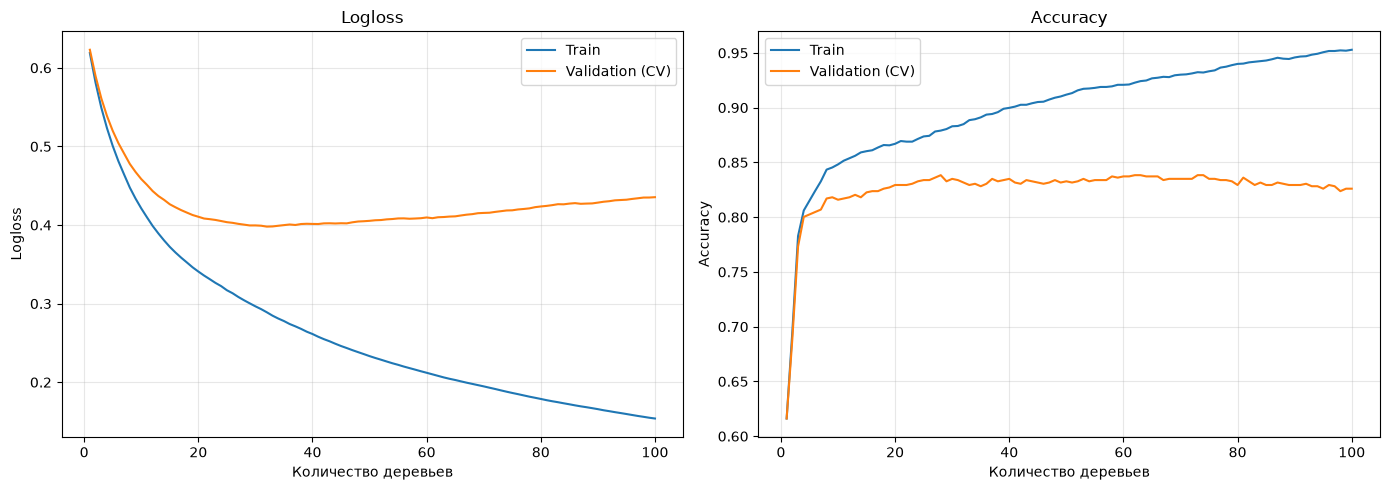

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric, title in zip(
    axes,
    ["binary_logloss", "binary_error"],
    ["Logloss", "Accuracy"],
):
    for group, label, color in [
        ("train", "Train", "tab:blue"),
        ("valid", "Validation (CV)", "tab:orange"),
    ]:
        values = np.mean([curve[group][metric] for curve in lgbm_curves], axis=0)
        if metric == "binary_error":
            values = 1 - values  # accuracy = 1 - доля ошибок

        ax.plot(range(1, len(values) + 1), values, label=label, color=color)

    ax.set(title=title, xlabel="Количество деревьев", ylabel=title)
    ax.grid(alpha=0.3)
    ax.legend()

fig.tight_layout()
plt.show()

Train Logloss продолжает уменьшаться, а validation Logloss примерно после 30–40 деревьев растёт; CV accuracy выходит на плато. Это повод проверить число деревьев и ограничить сложность их листьев.

### Подбор параметров

Совместно проверяем `n_estimators`, `learning_rate`, `num_leaves` и `min_child_samples`: число и шаг деревьев влияют друг на друга, а последние два параметра ограничивают сложность. Выбираем по CV accuracy; ROC-AUC смотрим дополнительно. Ниже — 10 лучших строк из 252 комбинаций.

In [32]:
lgbm_grid = GridSearchCV(
    estimator=LGBMClassifier(random_state=42, verbosity=-1),
    param_grid={
        "n_estimators": [20, 30, 40, 60, 100, 120, 200],
        "num_leaves": [7, 15, 31],
        "min_child_samples": [10, 20, 40],
        "learning_rate": [0.03, 0.05, 0.1, 0.2],
    },
    scoring={"accuracy": "accuracy", "roc_auc": "roc_auc"},
    refit="accuracy",
    cv=get_cv(),
    n_jobs=1,
)

lgbm_grid.fit(X_lgbm, y_lgbm)

lgbm_search_results = pd.DataFrame(lgbm_grid.cv_results_)
lgbm_search_results[
    [
        "param_n_estimators",
        "param_num_leaves",
        "param_min_child_samples",
        "param_learning_rate",
        "mean_test_accuracy",
        "std_test_accuracy",
        "mean_test_roc_auc",
    ]
].sort_values("mean_test_accuracy", ascending=False).head(10)

,param_n_estimators,param_num_leaves,param_min_child_samples,param_learning_rate,mean_test_accuracy,std_test_accuracy,mean_test_roc_auc
236,30,31,40,0.20,0.842872,0.016669,0.877575
99,120,7,20,0.05,0.842860,0.022556,0.875819
39,200,7,20,0.03,0.841736,0.019696,0.874615
121,120,15,40,0.05,0.840619,0.018401,0.876423
40,200,15,20,0.03,0.840606,0.018829,0.880375
97,100,15,20,0.05,0.840600,0.023887,0.881107
96,100,7,20,0.05,0.840600,0.023887,0.875385
165,200,7,20,0.10,0.840594,0.019879,0.878136
235,30,15,40,0.20,0.839502,0.019688,0.878553
185,120,31,40,0.10,0.839495,0.022147,0.879854


In [33]:
best_lgbm_row = lgbm_search_results.iloc[lgbm_grid.best_index_]
print("Лучшие параметры:", lgbm_grid.best_params_)
print(f"CV accuracy: {best_lgbm_row['mean_test_accuracy']:.4f} ± {best_lgbm_row['std_test_accuracy']:.4f}")
print(f"CV ROC-AUC: {best_lgbm_row['mean_test_roc_auc']:.4f}")

Лучшие параметры: {'learning_rate': 0.2, 'min_child_samples': 40, 'n_estimators': 30, 'num_leaves': 31}
CV accuracy: 0.8429 ± 0.0167
CV ROC-AUC: 0.8776


### Важность признаков

`GridSearchCV` уже переобучил лучший вариант на всём train. Показываем важность по `gain` — суммарному улучшению функции потерь в разбиениях по признаку. Это не причинный эффект и не изменение CV accuracy при удалении признака.

In [34]:
best_lgbm = lgbm_grid.best_estimator_

lgbm_importance = pd.Series(
    best_lgbm.booster_.feature_importance(importance_type="gain"),
    index=best_lgbm.booster_.feature_name(),
).sort_values(ascending=False)

lgbm_importance

Sex         789.429343
Age         376.850667
Fare        319.827918
Pclass      272.691570
Embarked     54.761464
SibSp        54.226206
Parch         5.780095
dtype: float64

Text(0.5, 0, 'Суммарный gain')

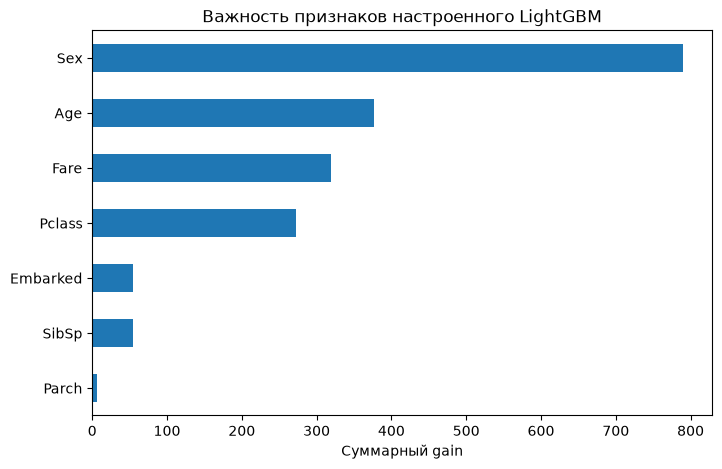

In [35]:
ax = lgbm_importance.sort_values().plot.barh(
    figsize=(8, 5),
    title="Важность признаков настроенного LightGBM",
)
ax.set_xlabel("Суммарный gain")

### LightGBM — итог

- Встроенная обработка категорий дала результат, близкий к общей предобработке: **0.8260** против **0.8271** CV accuracy.
- Подбор повысил CV accuracy до **0.8429 ± 0.0167** (`learning_rate=0.2`, 30 деревьев, `num_leaves=31`, `min_child_samples=40`), при ROC-AUC **0.8776**. Разница с лучшими соседними конфигурациями мала.
- Кривые baseline показывают переобучение при увеличении числа деревьев. По `gain` лидируют `Sex`, `Age`, `Fare`, `Pclass`; проверять новые признаки или удаление старых нужно отдельным CV-экспериментом.

## XGBoost

Сначала измеряем baseline на семи исходных признаках с общей предобработкой и теми же пятью фолдами, что использовали для Random Forest. Затем смотрим кривые обучения: они подскажут, какие параметры проверять.

In [36]:
from xgboost import XGBClassifier

xgb_baseline = evaluate_model(
    df=df_train,
    target="Survived",
    model=XGBClassifier(random_state=42, eval_metric="logloss"),
    config=rf_config,
)

xgb_baseline

{'accuracy_mean': np.float64(0.811436821291821),
 'accuracy_std': np.float64(0.02534917550248845),
 'roc_auc_mean': np.float64(0.871386950762464),
 'roc_auc_std': np.float64(0.022981054980569418)}

### Кривые обучения

На каждом из общих пяти фолдов обучаем предобработку только на train-части, затем записываем метрики XGBoost на train и validation после каждого дерева. Графики показывают среднее по фолдам; `test.csv` Kaggle здесь не используется.

In [37]:
from src.sklearn_experiments import build_experiment


def collect_xgb_cv_curves(pipeline, X, y):
    '''Собирает train и validation метрики по деревьям на общих CV-фолдах.'''
    curves = []
    for train_idx, valid_idx in get_cv().split(X, y):
        X_train_fold = X.iloc[train_idx]
        X_valid_fold = X.iloc[valid_idx]
        y_train_fold = y.iloc[train_idx]
        y_valid_fold = y.iloc[valid_idx]

        preprocessor = clone(pipeline.named_steps["preprocessor"])
        X_train_prepared = preprocessor.fit_transform(X_train_fold, y_train_fold)
        X_valid_prepared = preprocessor.transform(X_valid_fold)

        fold_model = clone(pipeline.named_steps["model"])
        fold_model.set_params(eval_metric=["logloss", "error"])
        fold_model.fit(
            X_train_prepared,
            y_train_fold,
            eval_set=[
                (X_train_prepared, y_train_fold),
                (X_valid_prepared, y_valid_fold),
            ],
            verbose=False,
        )
        curves.append(fold_model.evals_result())
    return curves


X_xgb, y_xgb, xgb_pipeline = build_experiment(
    df=df_train,
    target="Survived",
    model=XGBClassifier(random_state=42, eval_metric=["logloss", "error"], n_jobs=1),
    config=rf_config,
)
xgb_curves = collect_xgb_cv_curves(xgb_pipeline, X_xgb, y_xgb)

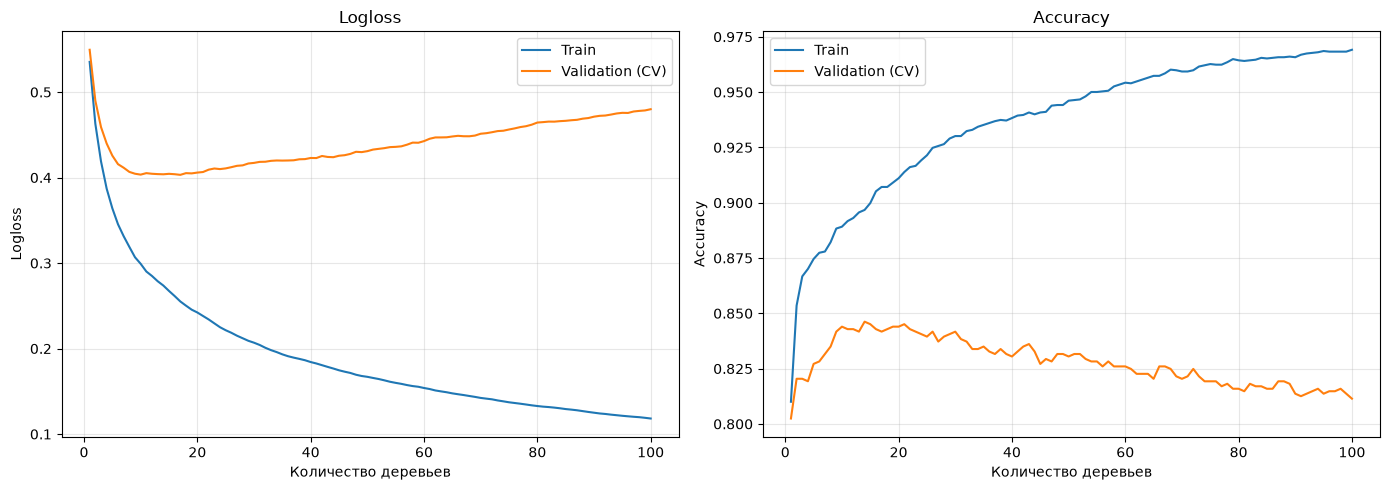

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

for ax, metric, title in zip(
    axes,
    ["logloss", "error"],
    ["Logloss", "Accuracy"],
):
    for group, label, color in [
        ("validation_0", "Train", "tab:blue"),
        ("validation_1", "Validation (CV)", "tab:orange"),
    ]:
        values = np.mean([curve[group][metric] for curve in xgb_curves], axis=0)
        if metric == "error":
            values = 1 - values

        ax.plot(range(1, len(values) + 1), values, label=label, color=color)

    ax.set(title=title, xlabel="Количество деревьев", ylabel=title)
    ax.grid(alpha=0.3)
    ax.legend()

fig.tight_layout()
plt.show()

### Подбор параметров

Начальная сетка: число деревьев и `learning_rate` задают темп обучения; `max_depth` и `min_child_weight` ограничивают сложность дерева. После просмотра кривых можно сузить диапазоны. Выбираем по CV accuracy на общих фолдах; предобработка находится внутри pipeline и заново обучается на каждом train-фолде.

In [39]:
xgb_grid = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid={
        "model__n_estimators": [40, 80, 120],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3, 4],
        "model__min_child_weight": [1, 5],
    },
    scoring={"accuracy": "accuracy", "roc_auc": "roc_auc"},
    refit="accuracy",
    cv=get_cv(),
    n_jobs=1,
)

xgb_grid.fit(X_xgb, y_xgb)

xgb_search_results = pd.DataFrame(xgb_grid.cv_results_)
xgb_search_results[[
    "param_model__n_estimators",
    "param_model__learning_rate",
    "param_model__max_depth",
    "param_model__min_child_weight",
    "mean_test_accuracy",
    "std_test_accuracy",
    "mean_test_roc_auc",
]].sort_values("mean_test_accuracy", ascending=False).head(10)

,param_model__n_estimators,param_model__learning_rate,param_model__max_depth,param_model__min_child_weight,mean_test_accuracy,std_test_accuracy,mean_test_roc_auc
34,80,0.10,4,5,0.842866,0.020767,0.875820
35,120,0.10,4,5,0.838372,0.019999,0.878473
17,120,0.05,4,5,0.837248,0.017155,0.874134
32,120,0.10,4,1,0.836118,0.021866,0.871685
31,80,0.10,4,1,0.836112,0.021611,0.868725
14,120,0.05,4,1,0.834995,0.018497,0.869689
29,120,0.10,3,5,0.832760,0.021522,0.871324
26,120,0.10,3,1,0.831649,0.014655,0.873755
13,80,0.05,4,1,0.831630,0.015675,0.873082
28,80,0.10,3,5,0.830513,0.022683,0.869400


In [40]:
best_xgb_row = xgb_search_results.iloc[xgb_grid.best_index_]
print("Лучшие параметры:", xgb_grid.best_params_)
print(f"CV accuracy: {best_xgb_row['mean_test_accuracy']:.4f} ± {best_xgb_row['std_test_accuracy']:.4f}")
print(f"CV ROC-AUC: {best_xgb_row['mean_test_roc_auc']:.4f}")

Лучшие параметры: {'model__learning_rate': 0.1, 'model__max_depth': 4, 'model__min_child_weight': 5, 'model__n_estimators': 80}
CV accuracy: 0.8429 ± 0.0208
CV ROC-AUC: 0.8758


### Кривые настроенного XGBoost

Повторяем графики для выбранных сеткой параметров. Используем те же пять фолдов и обучаем предобработку заново внутри каждого из них; выбор параметров уже сделан по этим фолдам, поэтому графики служат диагностикой, а не независимой оценкой качества.

In [41]:
xgb_tuned_curves = collect_xgb_cv_curves(xgb_grid.best_estimator_, X_xgb, y_xgb)

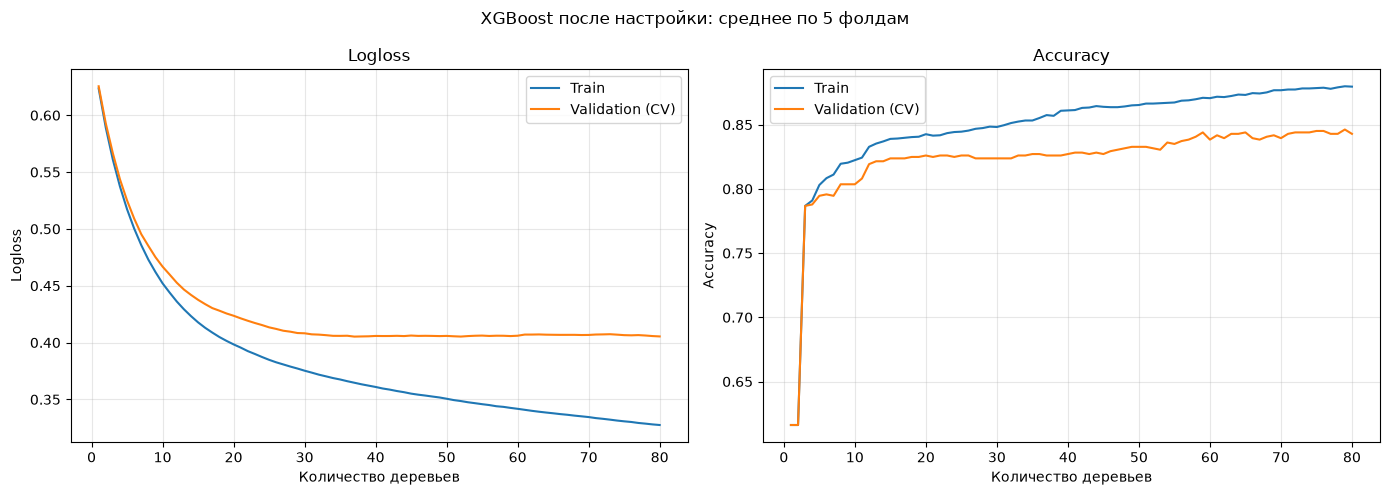

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

for ax, metric, title in zip(axes, ["logloss", "error"], ["Logloss", "Accuracy"]):
    for group, label, color in [
        ("validation_0", "Train", "tab:blue"),
        ("validation_1", "Validation (CV)", "tab:orange"),
    ]:
        values = np.mean([curve[group][metric] for curve in xgb_tuned_curves], axis=0)
        if metric == "error":
            values = 1 - values
        ax.plot(range(1, len(values) + 1), values, label=label, color=color)

    ax.set(title=title, xlabel="Количество деревьев", ylabel=title)
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle("XGBoost после настройки: среднее по 5 фолдам")
fig.tight_layout()
plt.show()

### Важность признаков

Лучший pipeline после `GridSearchCV` уже обучен на всём `train.csv`. Показываем `total_gain` по признакам **после предобработки**: категории `Embarked` представлены отдельными колонками. Это подсказка для гипотез, а не эффект удаления признака на CV accuracy.

In [43]:
best_xgb_pipeline = xgb_grid.best_estimator_
xgb_feature_names = best_xgb_pipeline.named_steps["preprocessor"].get_feature_names_out()
xgb_gain = best_xgb_pipeline.named_steps["model"].get_booster().get_score(
    importance_type="total_gain"
)
xgb_importance = pd.Series(
    [xgb_gain.get(f"f{i}", 0.0) for i in range(len(xgb_feature_names))],
    index=xgb_feature_names,
).sort_values(ascending=False)

xgb_importance

binary__Sex_male        1511.239746
numeric__Fare            524.318054
numeric__Pclass          486.128815
numeric__Age             468.681152
numeric__SibSp            77.729240
onehot__Embarked_S        58.878334
onehot__Embarked_C        20.153683
numeric__Parch            18.615326
onehot__Embarked_Q         0.000000
onehot__Embarked_nan       0.000000
dtype: float64

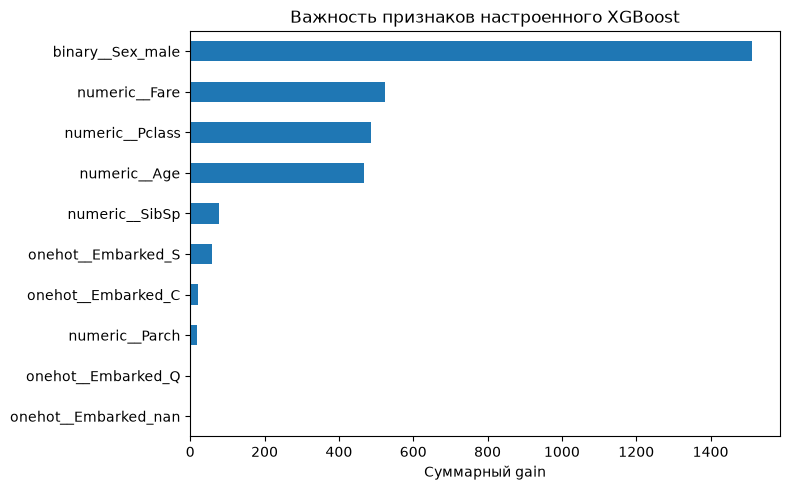

In [44]:
fig, ax = plt.subplots(figsize=(8, 5))
xgb_importance.sort_values().plot.barh(ax=ax)
ax.set(title="Важность признаков настроенного XGBoost", xlabel="Суммарный gain")
fig.tight_layout()
plt.show()

## Кривые трёх бустингов

Сводим уже построенные кривые в одну фигуру: **настроенный CatBoost**, **baseline LightGBM** со встроенными категориями и **настроенный XGBoost** с общей предобработкой. Сравниваем форму train/validation кривых, а не значения метрик в одинаковой точке оси X: число деревьев, параметры, обработка признаков и способ CV у CatBoost отличаются.

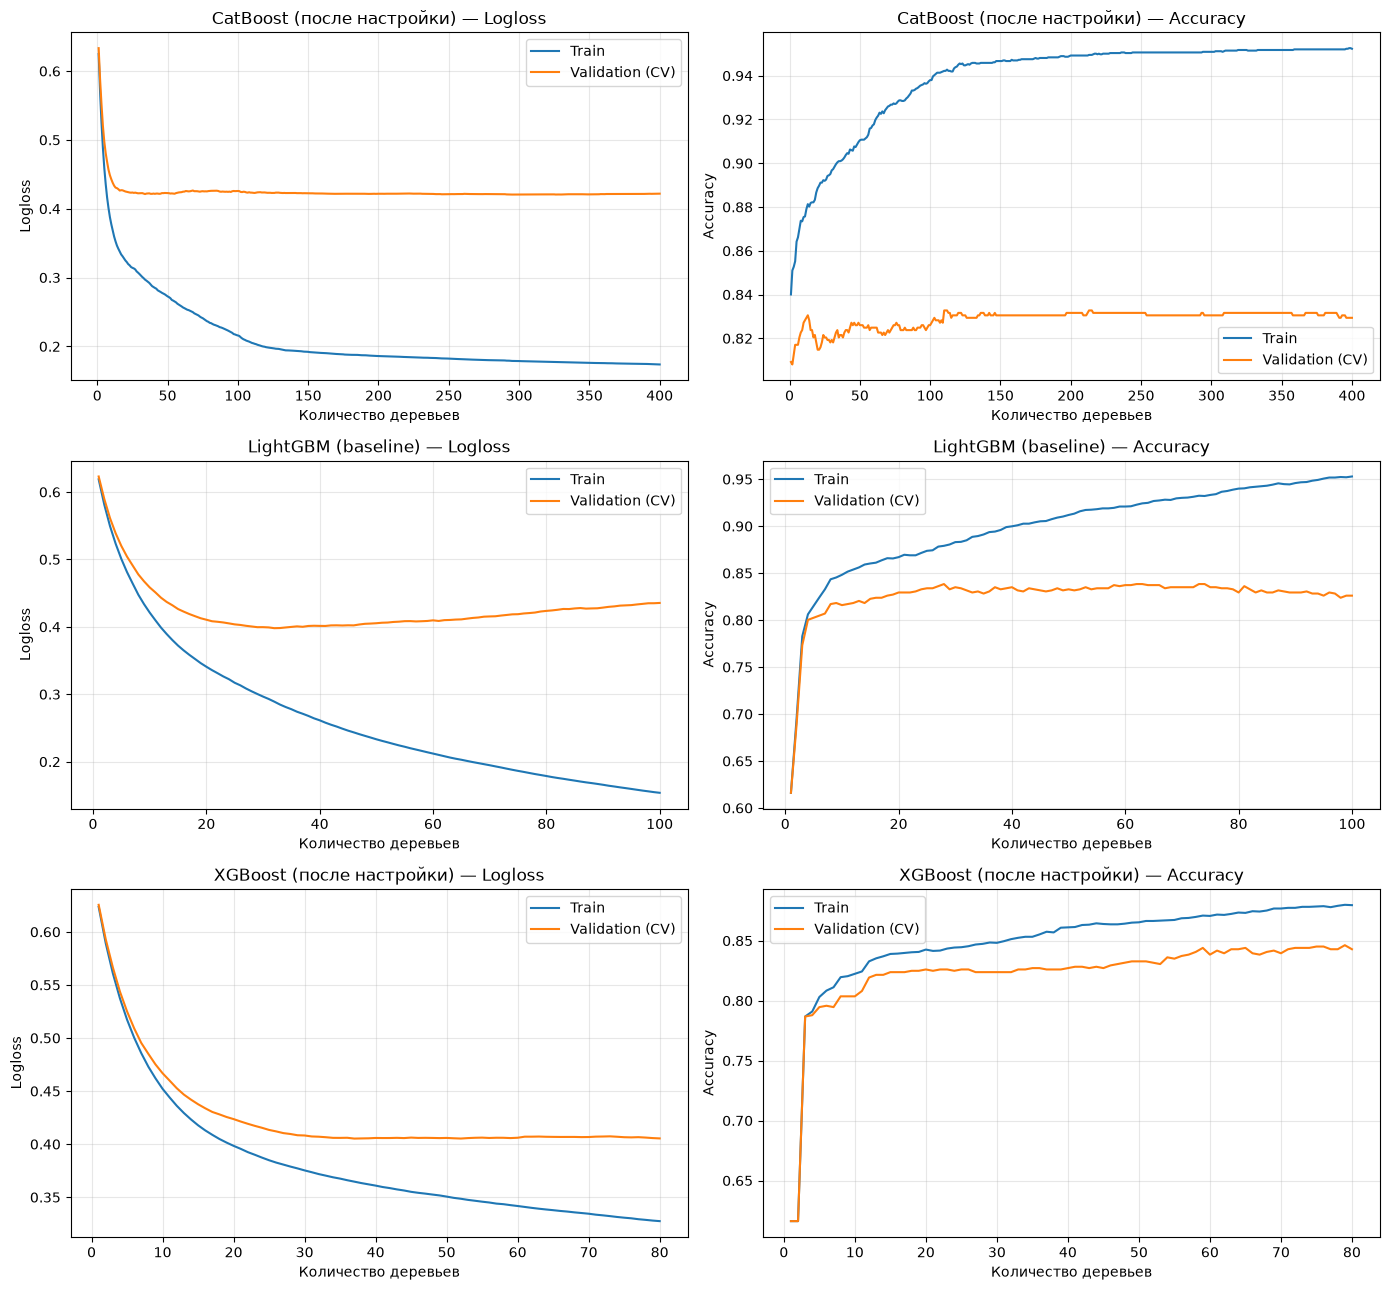

In [45]:
fig, axes = plt.subplots(3, 2, figsize=(14, 13))

boosting_curves = [
    (
        "CatBoost (после настройки)",
        tuned_cv_results["iterations"] + 1,
        {
            "Logloss": (
                tuned_cv_results["train-Logloss-mean"],
                tuned_cv_results["test-Logloss-mean"],
            ),
            "Accuracy": (
                tuned_cv_results["train-Accuracy-mean"],
                tuned_cv_results["test-Accuracy-mean"],
            ),
        },
    ),
    (
        "LightGBM (baseline)",
        range(1, len(lgbm_curves[0]["train"]["binary_logloss"]) + 1),
        {
            "Logloss": tuple(
                np.mean([curve[group]["binary_logloss"] for curve in lgbm_curves], axis=0)
                for group in ("train", "valid")
            ),
            "Accuracy": tuple(
                1 - np.mean([curve[group]["binary_error"] for curve in lgbm_curves], axis=0)
                for group in ("train", "valid")
            ),
        },
    ),
    (
        "XGBoost (после настройки)",
        range(1, len(xgb_tuned_curves[0]["validation_0"]["logloss"]) + 1),
        {
            "Logloss": tuple(
                np.mean([curve[group]["logloss"] for curve in xgb_tuned_curves], axis=0)
                for group in ("validation_0", "validation_1")
            ),
            "Accuracy": tuple(
                1 - np.mean([curve[group]["error"] for curve in xgb_tuned_curves], axis=0)
                for group in ("validation_0", "validation_1")
            ),
        },
    ),
]

for row, (model_name, iterations, metrics) in enumerate(boosting_curves):
    for col, metric in enumerate(("Logloss", "Accuracy")):
        ax = axes[row, col]
        train_values, valid_values = metrics[metric]
        ax.plot(iterations, train_values, label="Train", color="tab:blue")
        ax.plot(iterations, valid_values, label="Validation (CV)", color="tab:orange")
        ax.set(title=f"{model_name} — {metric}", xlabel="Количество деревьев", ylabel=metric)
        ax.grid(alpha=0.3)
        ax.legend()

fig.tight_layout()
plt.show()

У baseline LightGBM validation Logloss растёт примерно после 30–40 деревьев; у настроенного CatBoost она выходит на плато. У настроенного XGBoost validation Logloss почти перестаёт снижаться после ~35 деревьев, но accuracy медленно растёт до 80. Во всех случаях train продолжает улучшаться, поэтому разрыв с validation увеличивается. По этим графикам нельзя выбрать «лучший бустинг»: показаны разные конфигурации и обработка, а CatBoost запускался своим способом CV. Для итогового качества смотрим отдельную таблицу CV accuracy.

### XGBoost — итог

- Baseline: **0.8114 ± 0.0253** CV accuracy; после сетки: **0.8429 ± 0.0208**, ROC-AUC **0.8758**.
- Лучший проверенный вариант: 80 деревьев, `learning_rate=0.1`, `max_depth=4`, `min_child_weight=5`. Соседние комбинации близки по качеству; максимум сетки может быть оптимистичным.
- Настройка заметно уменьшила переобучение по сравнению с baseline-графиком. По `total_gain` впереди `Sex`, `Fare`, `Pclass`, `Age`; удаление остальных признаков требует отдельной CV-проверки.

### LightGBM — проверка HasCabin

Проверяем один новый признак на уже готовом baseline с общей предобработкой (`lgbm_preprocessed_baseline`). Параметры модели, обработка остальных колонок и фолды остаются прежними.

In [ ]:
df_with_cabin = df_train.assign(HasCabin=df_train["Cabin"].notna().astype(int))

lgbm_cabin_config = {
    "features": {
        "Age": "numeric",
        "Fare": "numeric",
        "Sex": "binary",
        "Embarked": "onehot",
        "Pclass": "numeric",
        "SibSp": "numeric",
        "Parch": "numeric",
        "_HasCabin": "numeric"
    },
    "scale_numeric": False,
    "is_alone": False,
    "is_child": False,
    "fare_log1p": False,
    "age_squared": False,
    "sex_pclass": True
}


evaluate_model(
    df=df_with_cabin,
    target="Survived"
    model=LGBMClassifier(random_state=42, verbosity=-1),
    config=lgbm_cabin_config,
)

{'accuracy_mean': np.float64(0.8282593685267718),
 'accuracy_std': np.float64(0.019510522605854622),
 'roc_auc_mean': np.float64(0.8809242872186044),
 'roc_auc_std': np.float64(0.02486998752319674)}

## Сравнение готовых решений

В таблице показан лучший вариант **каждого пайплайна**, включая выбранные признаки и обработку. Это сравнение итогового качества решений, а не чистого влияния алгоритма.

| Модель | Признаки и обработка | CV accuracy ± std | Разбиение |
| --- | --- | ---: | --- |
| DummyClassifier | Правило частого класса | 0.6162 ± 0.0023 | общие фолды |
| Logistic Regression | 6 исходных + 4 новых; масштабирование | 0.8159 ± 0.0081 | общие фолды |
| KNN | 6 исходных + `FamilySize`; масштабирование | 0.8317 ± 0.0086 | общие фолды |
| Decision Tree | 7 исходных + `SexPclass` | 0.8429 ± 0.0202 | общие фолды |
| Random Forest | 7 исходных; общая предобработка | **0.8462 ± 0.0211** | общие фолды |
| LightGBM, после поиска | 7 исходных; встроенные категории | 0.8429 ± 0.0167 | общие фолды |
| XGBoost, после поиска | 7 исходных; общая предобработка | 0.8429 ± 0.0208 | общие фолды |
| CatBoost, после поиска | 7 исходных; встроенные категории | 0.8328 ± 0.0398 | другие фолды CatBoost |
| CatBoost + `Title`, 110 деревьев | 7 исходных + `Title`; встроенные категории | 0.8316 ± 0.0466 | фолды эксперимента с признаками CatBoost |

На общих фолдах максимальный CV accuracy у пайплайна Random Forest, но близкие результаты LightGBM и XGBoost не позволяют приписать разницу только алгоритму: обработка признаков тоже различается. Строки CatBoost на другом разбиении служат ориентиром, а максимумы после подбора параметров могут быть оптимистичными.